# Random Forest

Ensemble of decision trees. Each tree is trained on a bootstrap sample of the rows and, at every split, considers only a random subset of features (`sqrt(n_features)` by default). Prediction is a majority vote across trees. Averaging many decorrelated, overfit trees cuts variance.

Self-contained: includes its own small tree (the plain one is in `15_decision_tree`).

## Usage

```python
# (the class is defined in the Implementation section below)

model = RandomForestClassifier(n_estimators=25, max_depth=8).fit(X_train, y_train)
preds = model.predict(X_test)
```

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
import numpy as np


def _gini(y, n_classes):
    probs = np.bincount(y, minlength=n_classes) / len(y)
    return 1.0 - np.sum(probs**2)


class _Tree:
    """CART tree that only considers a random subset of features at each split."""

    def __init__(self, max_depth, min_samples_split, max_features, n_classes, rng):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.max_features = max_features
        self.n_classes = n_classes
        self.rng = rng
        self.root = None

    def fit(self, X, y):
        self.root = self._grow(X, y, depth=0)
        return self

    def predict(self, X):
        return np.array([self._traverse(x, self.root) for x in X])

    def _leaf(self, y):
        return np.bincount(y, minlength=self.n_classes).argmax()

    def _grow(self, X, y, depth):
        if depth >= self.max_depth or len(y) < self.min_samples_split or len(np.unique(y)) == 1:
            return self._leaf(y)

        parent = _gini(y, self.n_classes)
        best_gain, best_feature, best_threshold = 0.0, None, None
        features = self.rng.choice(X.shape[1], self.max_features, replace=False)

        for f in features:
            values = np.unique(X[:, f])
            for t in (values[:-1] + values[1:]) / 2:  # midpoints between neighbours
                mask = X[:, f] <= t
                n_left = mask.sum()
                weighted = (
                    n_left * _gini(y[mask], self.n_classes)
                    + (len(y) - n_left) * _gini(y[~mask], self.n_classes)
                ) / len(y)
                if parent - weighted > best_gain:
                    best_gain, best_feature, best_threshold = parent - weighted, f, t

        if best_feature is None:
            return self._leaf(y)

        mask = X[:, best_feature] <= best_threshold
        return (
            best_feature,
            best_threshold,
            self._grow(X[mask], y[mask], depth + 1),
            self._grow(X[~mask], y[~mask], depth + 1),
        )

    def _traverse(self, x, node):
        while isinstance(node, tuple):
            feature, threshold, left, right = node
            node = left if x[feature] <= threshold else right
        return node


class RandomForestClassifier:
    """Bagging of decision trees: bootstrap rows + random features per split, majority vote."""

    def __init__(self, n_estimators=25, max_depth=8, min_samples_split=2,
                 max_features="sqrt", random_state=0):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.max_features = max_features
        self.random_state = random_state
        self.classes_ = None
        self.trees = []

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        self.classes_, y_enc = np.unique(y, return_inverse=True)  # any label type works
        n_samples, n_features = X.shape
        n_classes = len(self.classes_)
        max_features = (
            max(1, int(np.sqrt(n_features))) if self.max_features == "sqrt" else self.max_features
        )

        rng = np.random.default_rng(self.random_state)
        self.trees = []
        for _ in range(self.n_estimators):
            idx = rng.integers(0, n_samples, n_samples)  # bootstrap sample (with replacement)
            tree = _Tree(self.max_depth, self.min_samples_split, max_features, n_classes, rng)
            self.trees.append(tree.fit(X[idx], y_enc[idx]))
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        votes = np.array([tree.predict(X) for tree in self.trees])  # (n_trees, n_samples)
        n_classes = len(self.classes_)
        winners = [np.bincount(col, minlength=n_classes).argmax() for col in votes.T]
        return self.classes_[winners]

## See it work

### 1. One tree vs a forest

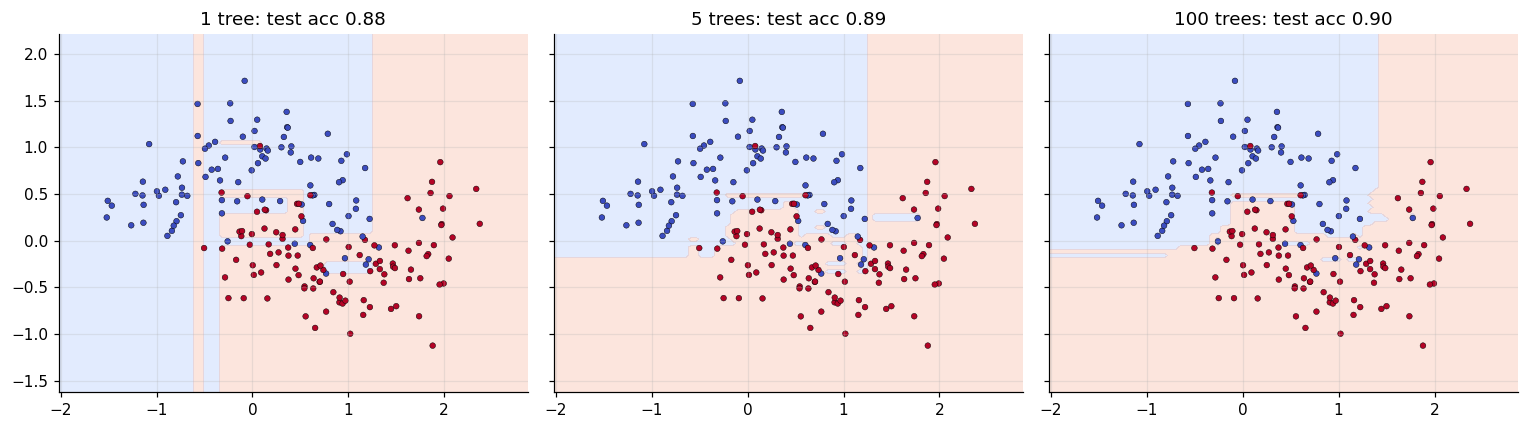

In [3]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
def plot_boundary(ax, model, X, y, cmap="coolwarm", n=150, pad=0.5):
    """Colour the plane by the model's predicted class, then draw the data on top."""
    gx, gy = np.meshgrid(np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, n), np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, n))
    pred = np.asarray(model.predict(np.c_[gx.ravel(), gy.ravel()])).reshape(gx.shape)
    K = len(np.unique(y))
    ax.contourf(gx, gy, pred, alpha=0.25, cmap=cmap, levels=np.arange(-0.5, K + 0.5) if K > 2 else [-0.5, 0.5, 1.5])
    ax.scatter(*X.T, c=y, cmap=cmap, s=14, edgecolor="k", linewidth=0.3)

Xm, ym = make_moons(n_samples=400, noise=0.3, random_state=0)
Xtr, Xte, ytr, yte = train_test_split(Xm, ym, test_size=0.5, random_state=0)
acc = lambda m, X, y: (m.predict(X) == y).mean()

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (name, m) in zip(axes, [("1 tree", RandomForestClassifier(n_estimators=1, max_depth=12)), ("5 trees", RandomForestClassifier(n_estimators=5, max_depth=12)), ("100 trees", RandomForestClassifier(n_estimators=100, max_depth=12))]):
    m.fit(Xtr, ytr); plot_boundary(ax, m, Xtr, ytr, n=90); ax.set_title(f"{name}: test acc {acc(m, Xte, yte):.2f}")
plt.tight_layout(); plt.show()

### 2. The extra ingredient: random feature subsets

At every split, a random forest considers only `max_features` randomly chosen features. That makes the trees **less alike** (each is forced to use different features), so averaging them removes more variance. Too few features per split makes each tree weaker; all features makes them near-copies (plain bagging). On this small dataset (wine, 13 features) the differences are within the noise (error bars overlap), a reminder that `max_features` is a knob to tune, not a rule:

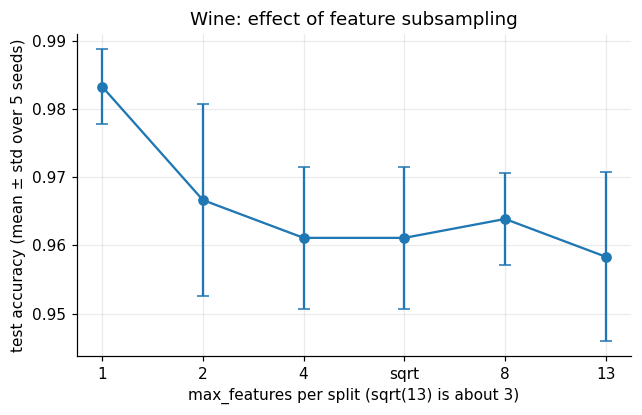

In [4]:
from sklearn.datasets import load_wine

wine = load_wine()
Xw_tr, Xw_te, yw_tr, yw_te = train_test_split(wine.data, wine.target, test_size=0.4, random_state=0)
mf = [1, 2, 4, "sqrt", 8, 13]
accs = []
for f in mf:
    runs = [(RandomForestClassifier(n_estimators=25, max_features=f, random_state=s).fit(Xw_tr, yw_tr).predict(Xw_te) == yw_te).mean() for s in range(5)]
    accs.append((np.mean(runs), np.std(runs)))
plt.figure(figsize=(6.5, 3.8)); plt.errorbar(range(len(mf)), [a for a, _ in accs], yerr=[s for _, s in accs], fmt="o-", capsize=4)
plt.xticks(range(len(mf)), [str(f) for f in mf]); plt.xlabel("max_features per split (sqrt(13) is about 3)"); plt.ylabel("test accuracy (mean ± std over 5 seeds)"); plt.title("Wine: effect of feature subsampling"); plt.show()

### 3. Accuracy vs number of trees

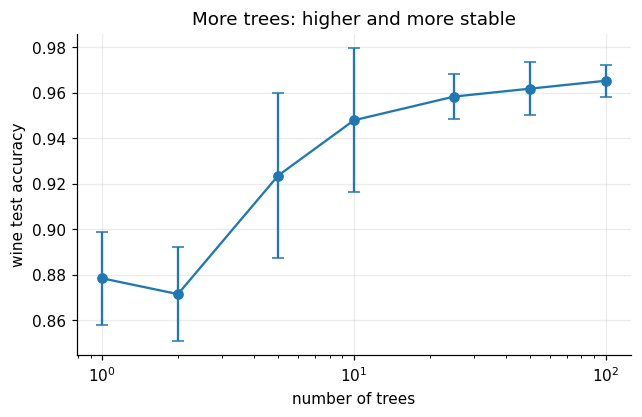

In [5]:
ns = [1, 2, 5, 10, 25, 50, 100]
runs = np.array([[(RandomForestClassifier(n_estimators=n, random_state=s).fit(Xw_tr, yw_tr).predict(Xw_te) == yw_te).mean() for n in ns] for s in range(4)])
plt.figure(figsize=(6.5, 3.8)); plt.errorbar(ns, runs.mean(0), yerr=runs.std(0), fmt="o-", capsize=4)
plt.xscale("log"); plt.xlabel("number of trees"); plt.ylabel("wine test accuracy"); plt.title("More trees: higher and more stable"); plt.show()

## Check against a reference implementation

Same data, same settings as scikit-learn (or scipy / the real library). The assertions fail if the two disagree.

In [6]:
from sklearn.datasets import load_wine
from sklearn.ensemble import RandomForestClassifier as SklearnRF
from sklearn.model_selection import train_test_split

data = load_wine()
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, test_size=0.3, random_state=42
)

ours = RandomForestClassifier(n_estimators=25, random_state=0).fit(X_train, y_train)
theirs = SklearnRF(n_estimators=25, random_state=0).fit(X_train, y_train)

acc_ours = (ours.predict(X_test) == y_test).mean()
acc_theirs = (theirs.predict(X_test) == y_test).mean()
print("wine test accuracy: ours=%.4f sklearn=%.4f" % (acc_ours, acc_theirs))
assert abs(acc_ours - acc_theirs) < 0.06  # forests are random: expect close, not identical

wine test accuracy: ours=1.0000 sklearn=0.9630


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [7]:
import numpy as np


def test_separated_clusters_with_string_labels():
    rng = np.random.default_rng(0)
    X = np.vstack([rng.normal(-3, 0.5, (60, 3)), rng.normal(3, 0.5, (60, 3))])
    y = np.array(["cat"] * 60 + ["dog"] * 60)

    model = RandomForestClassifier(n_estimators=10).fit(X, y)
    preds = model.predict(X)
    assert set(preds) <= {"cat", "dog"}
    assert (preds == y).mean() > 0.98


def test_iris_accuracy():
    from sklearn.datasets import load_iris
    from sklearn.model_selection import train_test_split

    data = load_iris()
    X_train, X_test, y_train, y_test = train_test_split(
        data.data, data.target, test_size=0.3, random_state=0
    )
    model = RandomForestClassifier(n_estimators=25, random_state=0).fit(X_train, y_train)
    assert (model.predict(X_test) == y_test).mean() > 0.9


def test_same_seed_same_forest():
    rng = np.random.default_rng(1)
    X = rng.normal(size=(80, 4))
    y = (X[:, 0] + X[:, 1] > 0).astype(int)
    a = RandomForestClassifier(n_estimators=5, random_state=7).fit(X, y).predict(X)
    b = RandomForestClassifier(n_estimators=5, random_state=7).fit(X, y).predict(X)
    assert (a == b).all()

In [8]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_separated_clusters_with_string_labels
PASS test_iris_accuracy
PASS test_same_seed_same_forest

all 3 tests passed


## Takeaways

- **Use it** as a strong default for tabular data: little tuning, handles mixed features, no scaling, robust to noise and overfitting (adding trees never overfits).
- **Two sources of randomness:** bootstrap rows (as in `18_bagging`) and a random feature subset at each split (`max_features`, default `√d` for classification). The second one decorrelates the trees.
- **Pitfalls:** big and slow to predict compared with one tree, not interpretable as a whole, cannot extrapolate. Boosting (`22`–`24`) often beats it when tuned.
- **Interview line:** *"Bagged decorrelated trees: bootstrap samples plus random feature subsets at each split; average the votes."*